# IADS5 · TP integrador — Ortelana Textil
### Actividad 13 · Comparativa y modelo candidato · Parcial 2

**Integrantes del grupo:** Camila Belén Capua, Franco Salama, Juan Pablo Ruax Debruijn, Lorena Wajchman, Tomas Rossi y Miguel Ángel Tadakuma  
**Comisión:** [Completar]  
**Repositorio GitHub:** https://github.com/francosalama/paa-integrador-ortelana  
**Fecha:** 17/11/2026

> Notebook independiente. Requiere el archivo `particion_train_test.csv` (partición train/test generada por `actividad_01.ipynb`).

## Actividad 13 · Comparativa y modelo candidato · Parcial 2

**Qué se espera:** Construí la tabla completa de modelos con media CV, std CV y métrica test histórica. Elegí un candidato y justificá en al menos 200 palabras desempeño, estabilidad, interpretación, costo y mantenimiento. Verificá pipeline y cinco predicciones.

**Evidencia a entregar:** Notebooks 01–13; tabla; justificación; commit `entrega-parcial-2`; tag `parcial-2`.

### TODO — Implementación libre
Desarrollá una solución propia. Organizá tantas celdas como necesites; incluí tablas y gráficos con títulos, ejes y unidades cuando correspondan. No alcanza con que el código ejecute: debe permitir comprobar las consignas.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)   # avisos de versión de librerías
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

df = pd.read_csv("ventas_historicas_ortelana_argentina.csv")

# Partición de la actividad 01: misma semilla, mismas filas de train y test
target = "Format_Reporte"
features = ["Sucursal_ID", "Tela_ID", "Año", "Metros1", "Metros2"]
train, test = train_test_split(df, test_size=0.2, stratify=df[target], random_state=RANDOM_STATE)

# Control: tiene que coincidir con la partición guardada en particion_train_test.csv
particion = pd.read_csv("particion_train_test.csv", index_col="fila")["particion"]
assert (particion[test.index] == "test").all() and (particion == "test").sum() == len(test)

X_train, X_test = train[features], test[features]
y_train, y_test = train[target], test[target]

print("Train:", X_train.shape, "| Test:", X_test.shape)


Train: (2628, 5) | Test: (657, 5)


In [2]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold, cross_val_score
from sklearn.metrics import accuracy_score, f1_score
import time

cat_cols = ["Sucursal_ID", "Tela_ID"]
num_cols = ["Año", "Metros1", "Metros2"]

def crear_pipeline(modelo):
    """Actividades 05-08: one-hot + numéricas sin cambios."""
    preprocesador = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
        ("num", "passthrough", num_cols)])
    return Pipeline([("prep", preprocesador), ("modelo", modelo)])

def crear_pipeline_completo(modelo, escalar=False):
    """Actividad 09 en adelante: imputación (+ escalado solo si el modelo lo necesita) / imputación + one-hot."""
    pasos_num = [("imputar", SimpleImputer(strategy="median"))]
    if escalar:
        pasos_num.append(("escalar", StandardScaler()))
    preprocesador = ColumnTransformer([
        ("num", Pipeline(pasos_num), num_cols),
        ("cat", Pipeline([("imputar", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat_cols)])
    return Pipeline([("preprocesamiento", preprocesador), ("modelo", modelo)])

# Regresión logística de la actividad 03: solo las variables numéricas, escaladas
logit = Pipeline([("prep", ColumnTransformer([("num", StandardScaler(), num_cols)])),
                  ("modelo", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))])

cv10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)

# CV agrupada por par (Sucursal, Tela): ningún par aparece a la vez en entrenamiento y validación.
# Mide la generalización a combinaciones nuevas, que el split aleatorio no puede medir.
grupos = X_train["Sucursal_ID"].astype(str) + "|" + X_train["Tela_ID"]
cv_grupos = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

In [3]:
# 13.1 Tabla completa: F1 macro de CV (10 folds, train), CV agrupada por par (5 folds, train) y test histórico
modelos = {
    "Baseline (clase más frecuente)": DummyClassifier(strategy="most_frequent"),
    "Regresión logística (numéricas)": logit,
    "Árbol gini (depth=4)": crear_pipeline(DecisionTreeClassifier(criterion="gini", max_depth=4, random_state=RANDOM_STATE)),
    "Árbol entropy (depth=4)": crear_pipeline(DecisionTreeClassifier(criterion="entropy", max_depth=4, random_state=RANDOM_STATE)),
    "Random Forest (100)": crear_pipeline(RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)),
    "Pipeline completo + Random Forest (100)": crear_pipeline_completo(RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)),
    "Random Forest solo volumen (sin Sucursal ni Tela)": Pipeline([
        ("prep", ColumnTransformer([("num", SimpleImputer(strategy="median"), num_cols)])),
        ("modelo", RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1))]),
    "k-NN k=5 sin escalado": crear_pipeline(KNeighborsClassifier(n_neighbors=5)),
    "k-NN k=1 con escalado": crear_pipeline_completo(KNeighborsClassifier(n_neighbors=1), escalar=True),   # k elegido en la actividad 11
}

def evaluar(modelo, y_entrenamiento, decodificar=lambda pred: pred):
    """CV estratificada aleatoria, CV agrupada por par y métrica de test histórica."""
    inicio = time.perf_counter()
    scores = cross_val_score(modelo, X_train, y_entrenamiento, cv=cv10, scoring="f1_macro")
    tiempo = time.perf_counter() - inicio
    scores_grupo = cross_val_score(modelo, X_train, y_entrenamiento, cv=cv_grupos, groups=grupos, scoring="f1_macro")
    pred = decodificar(modelo.fit(X_train, y_entrenamiento).predict(X_test))
    return {"F1 macro CV media": scores.mean(), "F1 macro CV desvío": scores.std(),
            "F1 macro CV por grupos (pares nuevos)": scores_grupo.mean(),
            "F1 macro test": f1_score(y_test, pred, average="macro"),
            "Accuracy test": accuracy_score(y_test, pred), "Tiempo CV (s)": tiempo}

filas = [{"Modelo": nombre, **evaluar(modelo, y_train)} for nombre, modelo in modelos.items()]

# XGBoost va aparte porque necesita las clases como números
codificador = LabelEncoder().fit(y_train)
xgb = crear_pipeline(XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=3,
                                   random_state=RANDOM_STATE, n_jobs=-1, eval_metric="mlogloss"))
filas.append({"Modelo": "XGBoost (100, lr=0.1, depth=3)",
              **evaluar(xgb, codificador.transform(y_train), codificador.inverse_transform)})

tabla = pd.DataFrame(filas).set_index("Modelo").sort_values("F1 macro CV media", ascending=False)
tabla["caída al pasar a pares nuevos"] = tabla["F1 macro CV media"] - tabla["F1 macro CV por grupos (pares nuevos)"]
tabla.round(4)

,F1 macro CV media,F1 macro CV desvío,F1 macro CV por grupos (pares nuevos),F1 macro test,Accuracy test,Tiempo CV (s),caída al pasar a pares nuevos
Modelo,,,,,,,
k-NN k=1 con escalado,0.9859,0.0062,0.6981,0.9941,0.9939,0.2038,0.2878
Random Forest (100),0.9654,0.0109,0.6625,0.9751,0.9756,1.7089,0.3029
Pipeline completo + Random Forest (100),0.9649,0.0109,0.6430,0.9706,0.9711,1.8756,0.3219
k-NN k=5 sin escalado,0.9126,0.0149,0.8805,0.9162,0.9148,0.2024,0.0320
"XGBoost (100, lr=0.1, depth=3)",0.8698,0.0219,0.6564,0.8877,0.8889,3.0408,0.2134
Random Forest solo volumen (sin Sucursal ni Tela),0.8632,0.0198,0.8392,0.8657,0.8630,1.9784,0.0240
Regresión logística (numéricas),0.7104,0.0298,0.7100,0.7296,0.7336,0.2413,0.0004
Árbol gini (depth=4),0.6240,0.0303,0.5659,0.6460,0.6545,0.1274,0.0581
Árbol entropy (depth=4),0.6091,0.0408,0.5451,0.6101,0.6256,0.1400,0.0639


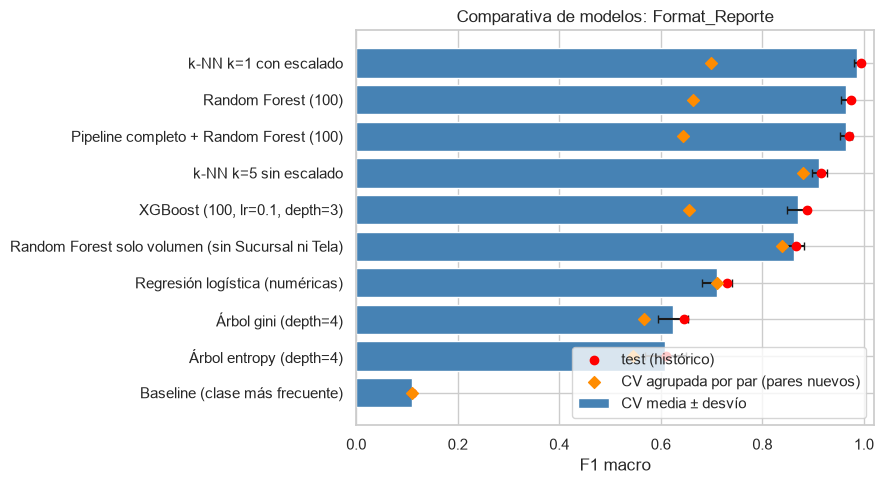

In [4]:
# 13.2 Visualización de la comparativa (media ± desvío de CV y test)
orden = tabla.sort_values("F1 macro CV media")
plt.figure(figsize=(9, 5))
plt.barh(orden.index, orden["F1 macro CV media"], xerr=orden["F1 macro CV desvío"], color="steelblue",
         capsize=3, label="CV media ± desvío")
plt.scatter(orden["F1 macro test"], orden.index, color="red", zorder=3, label="test (histórico)")
plt.scatter(orden["F1 macro CV por grupos (pares nuevos)"], orden.index, color="darkorange", marker="D", zorder=3,
            label="CV agrupada por par (pares nuevos)")
plt.title("Comparativa de modelos: Format_Reporte")
plt.xlabel("F1 macro")
plt.xlim(0, 1.02)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [5]:
# 13.3 Modelo candidato: pipeline completo (sin escalado) + Random Forest
from sklearn.base import clone

candidato = modelos["Pipeline completo + Random Forest (100)"]   # ya entrenado en 13.1
print("Pasos del pipeline:", [paso for paso, _ in candidato.steps])

# Verificación: reentrenar desde cero da exactamente las mismas predicciones
otro = clone(candidato).fit(X_train, y_train)
print("Mismas predicciones al reentrenar:", (otro.predict(X_test) == candidato.predict(X_test)).all())

# Cinco predicciones de prueba con sus probabilidades
cinco = X_test.head(5)
resultado = cinco.copy()
resultado["real"] = y_test.head(5)
resultado["predicción"] = candidato.predict(cinco)
probabilidades = pd.DataFrame(candidato.predict_proba(cinco), index=cinco.index,
                              columns=[f"P({c})" for c in candidato.classes_])
pd.concat([resultado, probabilidades.round(2)], axis=1)

Pasos del pipeline: ['preprocesamiento', 'modelo']


Mismas predicciones al reentrenar: True


,Sucursal_ID,Tela_ID,Año,Metros1,Metros2,real,predicción,P(B),P(C),P(M),P(S)
1127,5,TELA-001,2016,292.35,308.44,M,M,0.10,0.01,0.88,0.01
365,2,TELA-006,2018,2682.03,2106.97,C,C,0.00,0.97,0.00,0.03
1109,4,TELA-009,2025,1575.90,1150.65,C,C,0.00,0.90,0.00,0.10
1318,5,TELA-006,2023,1114.15,1152.13,S,S,0.03,0.04,0.00,0.93
2583,10,TELA-018,2019,1003.58,773.20,C,C,0.00,0.89,0.00,0.11


### Explicación del alumno/a

**Decisiones técnicas y justificación:**
- **Tabla:** reúne todos los modelos de clasificación con tres mediciones:
  - la misma CV estratificada de 10 folds sobre train (media y std), que es la que pide la consigna;
  - una **CV agrupada por par (Sucursal, Tela)** de 5 folds sobre train (`StratifiedGroupKFold`): ningún par aparece a la vez en entrenamiento y validación, así que mide qué pasa con combinaciones nuevas;
  - el F1 macro de test "histórico" y el tiempo de la CV.
- **Por qué agregamos la CV agrupada:** el formato es constante para cada par y el 100% de los pares de test está en train (Actividad 01). Con un split aleatorio, cualquier modelo que use `Sucursal_ID` y `Tela_ID` puede acertar recordando el par.
- **Modelo agregado:** un Random Forest **solo con volumen** (`Año`, `Metros1`, `Metros2`, sin identificadores), para medir cuánto de la métrica viene de los identificadores.

**Interpretación de los resultados:**
- **Con la CV aleatoria (la de la consigna):** k-NN k = 1 (0,986) > RF (0,965) ≈ Pipeline RF (0,965) > k-NN k = 5 sin escalar (0,913) > XGBoost (0,870) > RF solo volumen (0,863) > Logística (0,710) > Árbol gini (0,624) > Árbol entropy (0,609) > Baseline (0,110).
- **Con la CV agrupada por par, el orden se da vuelta:**
  - Los modelos que usan los identificadores se desploman: k-NN k = 1 cae a **0,698** (−0,29), el Pipeline RF a **0,643** (−0,32) y XGBoost a 0,656 (−0,21).
  - Los que se apoyan en el volumen casi no cambian: RF solo volumen 0,839 (−0,02), k-NN k = 5 sin escalar 0,881 (−0,03; sin escalado, los metros dominan la distancia y las dummies casi no pesan) y la logística 0,710 (sin cambio).
- **Conclusión:** con el split aleatorio, **tanto k-NN como Random Forest memorizan** el formato fijo de cada par sucursal–tela. El 0,96–0,99 de la CV aleatoria es memoria de pares conocidos, no capacidad de generalización. Ante pares nuevos, el modelo candidato rinde ~0,64, peor que la logística con solo tres variables.

**Candidato elegido: Pipeline completo + Random Forest (100 árboles)**, para el escenario que evalúa la consigna (pares conocidos, split aleatorio).
- **Desempeño:** F1 macro CV 0,9649 y test 0,971. La diferencia con k-NN k = 1 (0,986) es de ~2 puntos.
- **Por qué no k-NN k = 1:** no porque RF no memorice (los dos lo hacen), sino porque k = 1 está en el extremo de la grilla, es el ajuste de mayor varianza (un solo registro mal etiquetado se propaga), solo devuelve probabilidades 0 o 1 y depende del peso relativo de las dummies frente a las numéricas.
- **Estabilidad:** desvío de 0,011 entre folds, uno de los más bajos.
- **Interpretación:** ofrece importancias de variables y **probabilidades graduadas** por clase, que permiten detectar predicciones inciertas y derivarlas a revisión.
- **Robustez y simplicidad:** imputa faltantes, ignora categorías nuevas y no lleva escalado, porque es invariante a la escala (Actividad 09).
- **Costo y mantenimiento:** entrena en ~0,2 s, predice en milisegundos y es un único objeto de scikit-learn serializable con joblib, sin codificación aparte del target (XGBoost requiere el `LabelEncoder`).
- **Verificación (13.3):** el candidato reconstruido con `clone` reproduce exactamente sus predicciones, y las cinco predicciones de prueba son correctas, con probabilidades de entre 0,88 y 0,97 en la clase elegida.

**Este clasificador no debe pasar a producción para pares nuevos.**
- Para pares conocidos, el formato es constante en el histórico, así que alcanza con una tabla de búsqueda (par → formato), sin ningún modelo.
- Para sucursales o telas nuevas, el modelo no generaliza (0,64). Si Ortelana necesitara clasificar pares nuevos, la alternativa sería un modelo sin identificadores, como el RF solo con volumen (0,839 en la CV agrupada), validado con esa misma CV.

**Pregunta de análisis:** ¿Por qué elegís este modelo y no el que tiene la mejor métrica aislada?
- Porque la mejor métrica aislada (k-NN k = 1, 0,986) está inflada por pares repetidos entre train y validación, igual que la del RF: la CV agrupada lo muestra (0,698 y 0,643). Entre dos modelos que memorizan, elegimos el más estable, el que cuantifica su incertidumbre y el más simple de mantener.
- **Vínculo con la teoría:** la Unidad 6 asocia k = 1 con varianza alta y sobreajuste. La Unidad 5 indica elegir "por rendimiento, estabilidad y costo, no solo por el máximo F1", y la validación debe imitar el uso real: si el uso real incluye pares nuevos, la CV tiene que agrupar por par.

**Limitaciones o mejoras posibles:**
- Las métricas de la CV aleatoria y del test comparten el sesgo de pares repetidos. La CV agrupada es la referencia para datos realmente nuevos.
- Consultar el test en cada actividad, como pide el enunciado, ya expuso ese conjunto. Por eso la elección se basa en la CV y no en la columna de test.

### Comentarios del docente

[Espacio breve para observaciones sobre esta actividad: aciertos, correcciones o sugerencias.]